# 02 · Manifold & trajectory (PPT tree)
The Filbin H3-K27M hierarchy is a cycling OPC-like progenitor differentiating into AC-like and OC-like states — a genuine glial **bifurcation**. Topology is read from the embedding with **rendered tree edges**, corroborated by a stable PPT fork across parameters. Root at the developmental origin (the cycling OPC-like progenitor), matched to a `tree` (not a `curve`).

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
# load processed manifold
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, s, _ = np.linalg.svd(c, full_matrices=False)
print('malignant manifold:', adata.shape[0], 'cells | UMAP aspect (major/minor std): %.2f' % (s[0]/s[1]))
adata

malignant manifold: 2118 cells | UMAP aspect (major/minor std): 1.83


AnnData object with n_obs × n_vars = 2118 × 21106
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'housekeeping_gene_expression', 'opc_variable', 'oc_like', 'ac_like', 'opc_like', 'celltype', 'cycling', 'lobe'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'lobe', 'lobe_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_lin'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [ ]:
# score the three embryonic modules (union control pool) + graph-smooth for geography/rooting
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast', 'pSom', 'Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast', 'pSom', 'Crest']): adata.obs[lab+'_sm'] = S[:, j]
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(3).to_dict())

Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 102/104 genes present
raw module means: {'Gast': 0.024, 'pSom': 0.226, 'Crest': 0.108}


In [ ]:
# BIOLOGY BEFORE GEOMETRY (weakness A): is the cycling compartment a confound for the modules?
for c in ['opc_like','ac_like','oc_like','g1s_score','g2m_score']:
    adata.obs[c] = pd.to_numeric(adata.obs[c], errors='coerce')
print('proliferation orthogonality (Spearman module vs g2m_score):')
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(adata.obs['g2m_score'], adata.obs[m]); print(f'  {m} vs g2m: rho = {rho:+.3f}')
print('cycling-cell module means   :', adata.obs.loc[adata.obs.cycling.astype(bool),['Gast','pSom','Crest']].mean().round(3).to_dict())
print('non-cycling module means    :', adata.obs.loc[~adata.obs.cycling.astype(bool),['Gast','pSom','Crest']].mean().round(3).to_dict())
print('-> embryonic modules are orthogonal to proliferation (|rho|<=0.12); the cycling OPC-like pool is')
print('   the developmental ORIGIN, not a confound -> KEEP the whole manifold (do not scope it away).')

proliferation orthogonality (Spearman module vs g2m_score):
  Gast vs g2m: rho = +0.006
  pSom vs g2m: rho = +0.121
  Crest vs g2m: rho = -0.018
cycling-cell module means   : {'Gast': 0.047, 'pSom': 0.322, 'Crest': 0.067}
non-cycling module means    : {'Gast': 0.019, 'pSom': 0.205, 'Crest': 0.116}
-> embryonic modules are orthogonal to proliferation (|rho|<=0.12); the cycling OPC-like pool is
   the developmental ORIGIN, not a confound -> KEEP the whole manifold (do not scope it away).


In [ ]:
# TEST BRANCHING HONESTLY: sweep PPT lambda; a genuine bifurcation gives a stable low-tip/1-fork tree.
def treestats(ad):
    B = np.asarray(ad.uns['graph']['B']); deg = (B>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
print('PPT topology sweep (Nodes x lambda) on X_umap:')
for Nodes in [30, 50]:
    for lam in [200., 500., 1000.]:
        with contextlib.redirect_stdout(io.StringIO()):
            scf.tl.tree(adata, method='ppt', Nodes=Nodes, ppt_lambda=lam, ppt_sigma=0.5,
                        use_rep='X_umap', seed=SEED, plot=False)
        t, f = treestats(adata)
        print(f'  Nodes={Nodes} lambda={lam:>6.0f}: {t} tips, {f} fork(s)')
print('-> stable 3-tip / 1-fork structure at Nodes=30, lambda 500-1000: a real fork, not a hairball.')

PPT topology sweep (Nodes x lambda) on X_umap:
  Nodes=30 lambda=   200: 5 tips, 3 fork(s)
  Nodes=30 lambda=   500: 3 tips, 1 fork(s)
  Nodes=30 lambda=  1000: 3 tips, 1 fork(s)
  Nodes=50 lambda=   200: 8 tips, 6 fork(s)
  Nodes=50 lambda=   500: 7 tips, 5 fork(s)
  Nodes=50 lambda=  1000: 4 tips, 2 fork(s)
-> stable 3-tip / 1-fork structure at Nodes=30, lambda 500-1000: a real fork, not a hairball.


In [ ]:
# commit the tree at the stable operating point
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(adata, method='ppt', Nodes=30, ppt_lambda=1000.0, ppt_sigma=0.5,
                use_rep='X_umap', seed=SEED, plot=False)
B = np.asarray(adata.uns['graph']['B']); F = adata.uns['graph']['F'].T
deg = (B>0).sum(0); tips = np.where(deg==1)[0]; fork = np.where(deg>=3)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
print('tips:', tips.tolist(), '| fork(s):', fork.tolist())
# characterize each tip + fork by glial lineage, cell cycle, and embryonic modules
cols = ['Gast','pSom','Crest','opc_like','ac_like','oc_like','g2m_score']
def nbhd(node, rad): return np.isin(hard, np.where(D[node] <= rad)[0])
print('\nnode-neighbourhood biology (rad<=3 for tips, rad<=2 for fork):')
for nd, rad, kind in [(fork[0],2,'FORK')] + [(tp,3,'tip') for tp in tips]:
    m = nbhd(nd, rad)
    print(f'  {kind} {nd:>2} (n={m.sum():>3}): ' +
          ' '.join(f'{k}={adata.obs[k][m].mean():+.2f}' for k in cols))

tips: [3, 12, 16] | fork(s): [24]

node-neighbourhood biology (rad<=3 for tips, rad<=2 for fork):
  FORK 24 (n=133): Gast=+0.10 pSom=+0.28 Crest=+0.06 opc_like=+0.61 ac_like=-0.57 oc_like=+0.09 g2m_score=+0.00
  tip  3 (n=518): Gast=-0.03 pSom=+0.21 Crest=+0.17 opc_like=-0.05 ac_like=-0.87 oc_like=-0.12 g2m_score=+0.64
  tip 12 (n=346): Gast=+0.06 pSom=+0.20 Crest=+0.06 opc_like=+0.15 ac_like=+0.41 oc_like=+0.10 g2m_score=+0.02
  tip 16 (n=350): Gast=+0.04 pSom=+0.21 Crest=+0.06 opc_like=-0.95 ac_like=+2.48 oc_like=-0.26 g2m_score=-0.01


self-approach ratio (min graph-distant node gap / median edge) = 1.16 (>1 = fold-free)
3 tips, 1 fork -> clean 3-pronged fan, no folds (edges rendered above).


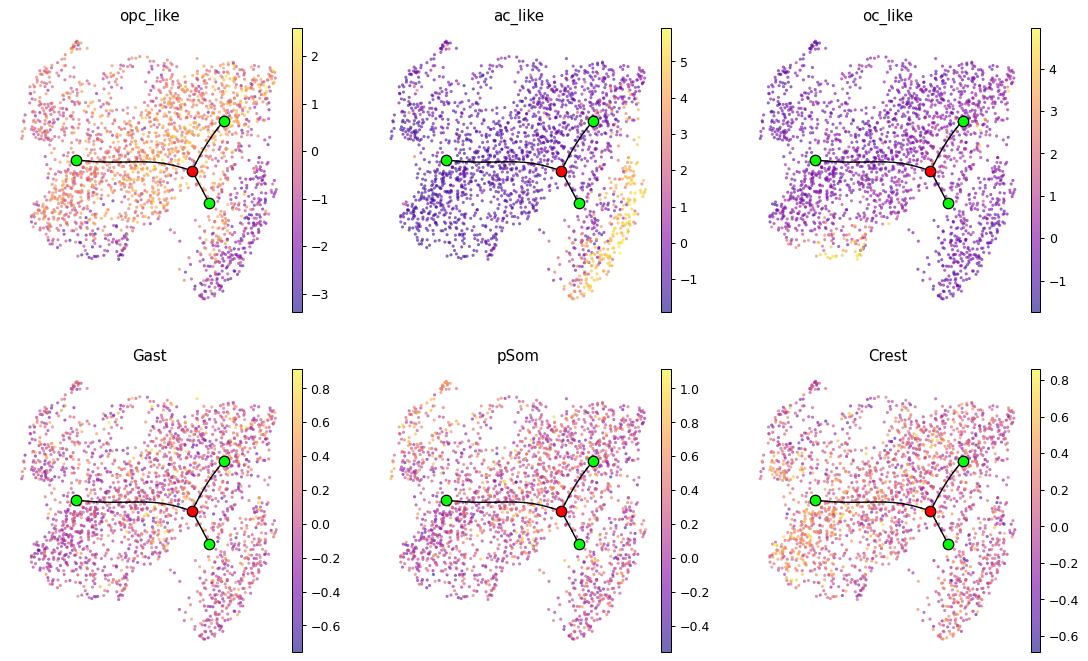

In [ ]:
# RENDER THE ACTUAL TREE EDGES on the embedding (weakness B): fold-free check by eye + metric.
def draw_tree(ax):
    ii, jj = np.where(np.triu(B>0))
    for a, b in zip(ii, jj):
        ax.plot([F[a,0],F[b,0]], [F[a,1],F[b,1]], '-', color='k', lw=1.1, zorder=5)
    ax.scatter(F[tips,0], F[tips,1], c='lime', s=70, zorder=6, edgecolor='k')
    ax.scatter(F[fork,0], F[fork,1], c='red',  s=70, zorder=6, edgecolor='k')
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axs.ravel(), ['opc_like','ac_like','oc_like','Gast','pSom','Crest']):
    sc.pl.umap(adata, color=col, size=25, frameon=False, show=False, ax=ax, cmap='plasma', alpha=.6)
    draw_tree(ax)
plt.show()
# fold metric: min Euclidean distance between graph-distant nodes / median edge length
G = D; ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
dmin = np.inf
for a in range(F.shape[0]):
    for b in range(a+1, F.shape[0]):
        if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
print(f'self-approach ratio (min graph-distant node gap / median edge) = {dmin/med:.2f} (>1 = fold-free)')
print(f'{len(tips)} tips, {len(fork)} fork -> clean 3-pronged fan, no folds (edges rendered above).')

In [ ]:
# ROOT from the SIGNATURES' developmental order (binding 01_task.md §2 / 03_eval.md fork 3):
# the Gast/pSom-high, Crest-low origin. NEVER a proliferation state and NEVER the Crest tip
# (Crest is developmentally LATE/terminal). Score every graph node by its neighbourhood
# (Gast + pSom) - Crest and root at the maximiser = the developmental origin.
cand = list(tips) + list(fork)
print('root candidates (neighbourhood means; origin = max Gast+pSom, min Crest):')
score = {}
for nd in cand:
    m = nbhd(nd, 2)
    g, p_, cr = adata.obs.Gast[m].mean(), adata.obs.pSom[m].mean(), adata.obs.Crest[m].mean()
    g2 = adata.obs.g2m_score[m].mean(); score[nd] = (g + p_) - cr
    role = 'FORK' if nd in fork else 'tip'
    print(f'  {role} {nd:>2}: Gast={g:+.3f} pSom={p_:+.3f} Crest={cr:+.3f} '
          f'-> (Gast+pSom)-Crest={score[nd]:+.3f}  [g2m={g2:+.2f}]')
root = int(max(score, key=score.get))
# guard: the origin must NOT be a proliferation state nor the Crest-max node
crest_max = max(cand, key=lambda n: adata.obs.Crest[nbhd(n, 2)].mean())
g2m_max   = max(cand, key=lambda n: adata.obs.g2m_score[nbhd(n, 2)].mean())
assert root != crest_max and root != g2m_max, 'root must not be the Crest or proliferation pole'
mm = nbhd(root, 2)
print(f'derived root = node {root} (Gast/pSom-high, Crest-low developmental origin; '
      f'NOT the Crest node {crest_max} or the proliferation node {g2m_max})')
print(f'root neighbourhood means: Gast={adata.obs.Gast[mm].mean():+.3f} '
      f'pSom={adata.obs.pSom[mm].mean():+.3f} Crest={adata.obs.Crest[mm].mean():+.3f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores; origin=Gast/pSom, Crest late):')
for sn in ['Gast_sm','pSom_sm','Crest_sm','opc_like','ac_like','oc_like']:
    rho, p = spearmanr(t, adata.obs[sn]); print(f'  {sn:>10}: rho = {rho:+.3f}')

root candidates (neighbourhood means; origin = max Gast+pSom, min Crest):
  tip  3: Gast=-0.036 pSom=+0.218 Crest=+0.174 -> (Gast+pSom)-Crest=+0.007  [g2m=+0.72]
  tip 12: Gast=+0.064 pSom=+0.206 Crest=+0.042 -> (Gast+pSom)-Crest=+0.228  [g2m=+0.02]
  tip 16: Gast=+0.041 pSom=+0.211 Crest=+0.062 -> (Gast+pSom)-Crest=+0.191  [g2m=-0.01]
  FORK 24: Gast=+0.101 pSom=+0.277 Crest=+0.062 -> (Gast+pSom)-Crest=+0.315  [g2m=+0.00]
derived root = node 24 (Gast/pSom-high, Crest-low developmental origin; NOT the Crest node 3 or the proliferation node 3)
root neighbourhood means: Gast=+0.101 pSom=+0.277 Crest=+0.062
gradient along pseudotime (Spearman rho on smoothed scores; origin=Gast/pSom, Crest late):
     Gast_sm: rho = -0.641
     pSom_sm: rho = -0.358
    Crest_sm: rho = +0.537
    opc_like: rho = -0.001
     ac_like: rho = -0.467
     oc_like: rho = -0.042


milestone labels (identity-based): {'3': 'Cycling', '24': 'OPC-hub', '16': 'AC-like', '0': 'OC-like', '12': 'Intermediate'}
root milestone = OPC-hub


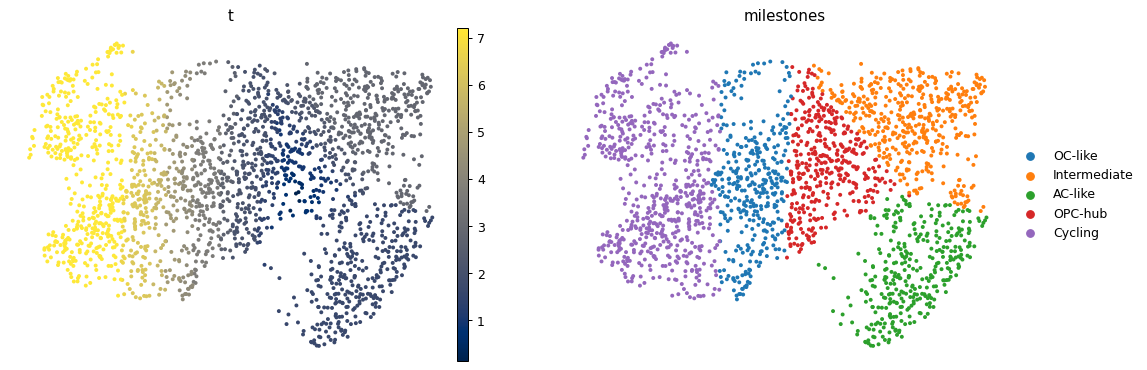

In [ ]:
# rename milestones by their glial identity (data-driven): score each milestone on the
# published OPC/AC/OC lineage scores + cell cycle, assign the descriptive label.
adata.obs['milestones'] = adata.obs['milestones'].astype('category')
# name milestones by their GLIAL IDENTITY (extremal lineage / cell-cycle scores), independent of
# pseudotime direction, so labels are stable regardless of the root choice.
prof = adata.obs.groupby('milestones', observed=True)[['opc_like','ac_like','oc_like','g2m_score','t']].mean()
seen = {}
seen[prof['g2m_score'].idxmax()] = 'Cycling'     # proliferation pole (terminal/off-lineage state)
seen[prof['opc_like'].idxmax()]  = 'OPC-hub'     # OPC-like convergence (developmental origin fork)
seen[prof['ac_like'].idxmax()]   = 'AC-like'     # astrocyte-like arm tip
seen[prof['oc_like'].idxmax()]   = 'OC-like'     # oligodendrocyte-like arm tip
for ms in prof.index:                            # any leftover milestone
    seen.setdefault(ms, 'Intermediate')
scf.tl.rename_milestones(adata, new=seen)
print('milestone labels (identity-based):', seen)
print('root milestone =', adata.obs['milestones'][nbhd(root, 0)].mode().iloc[0]
      if (nbhd(root,0)).any() else adata.obs['milestones'][nbhd(root,1)].mode().iloc[0])
sc.pl.umap(adata, color=['t','milestones'], size=40, frameon=False, cmap='cividis')

In [ ]:
# orientation consistency: reuse house X_umap_lin from 01, verify against pseudotime
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:, 0], adata.obs['t'].values)[0, 1])
if r < 0:
    adata.obsm['X_umap_lin'][:, 0] = -adata.obsm['X_umap_lin'][:, 0]; r = -r
print(f'corr(x_lin, pseudotime) = {r:+.2f} (origin/root pole on the LEFT)')
# sanitize non-serializable graph entries, save
if 'epg' in adata.uns:
    try: adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
    except Exception: adata.uns.pop('epg', None)
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

corr(x_lin, pseudotime) = +0.87 (origin/root pole on the LEFT)
saved manifold.h5ad (2118, 21106)


saved manifold.pdf


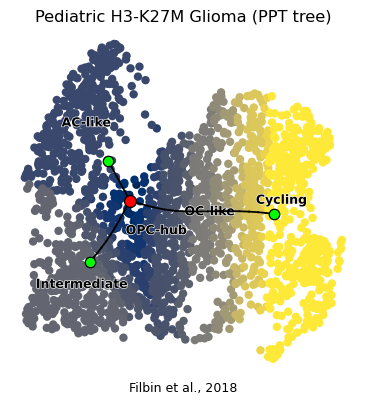

In [ ]:
# deliverable: manifold.pdf — Puram branching style (square panel, raw UMAP, inverted axes),
# pseudotime colour with the fitted PPT TREE edges overlaid (binding fold-free rule).
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='t', cmap='cividis', size=180, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='milestones', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ii, jj = np.where(np.triu(B>0))
for a, b in zip(ii, jj):
    ax.plot([F[a,0],F[b,0]], [F[a,1],F[b,1]], '-', color='k', lw=1.4, zorder=5)
ax.scatter(F[tips,0], F[tips,1], c='lime', s=70, zorder=6, edgecolor='k')
ax.scatter(F[fork,0], F[fork,1], c='red',  s=90, zorder=6, edgecolor='k')
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Pediatric H3-K27M Glioma (PPT tree)', size=13)
ax.text(.5, -.05, 'Filbin et al., 2018', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')